# Black Sigatoka Random Forest

Guided implementation of the approved synthetic risk-score experiment. Training and validation only; the held-out test CSV is not loaded for modeling.

## 1. Import Libraries



In [1]:
from pathlib import Path
import hashlib, json, tempfile, sys
import joblib, matplotlib.pyplot as plt, numpy as np, pandas as pd, seaborn as sns
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score, classification_report, confusion_matrix)
from sklearn.model_selection import ParameterGrid
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name.lower() == "notebooks": PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from black_sigatoka_preprocessing import FEATURES, TARGET, load_and_validate_datasets, prepare_model_inputs, risk_score_to_category

## 2. Record Checksums

Hash CSVs and the existing model to verify they remain unchanged. Test CSV bytes are hashed for integrity only; test rows are not loaded or modeled.

In [2]:
def sha256_file(path):
    digest=hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024*1024), b""): digest.update(block)
    return digest.hexdigest()
dataset_dir=PROJECT_ROOT/"datasets/black_sigatoka/revised_splits"
dataset_files=sorted(dataset_dir.glob("*.csv"))
saved_model_path=PROJECT_ROOT/"Models/black_sigatoka/random_forest/random_forest_model.joblib"
metadata_path=PROJECT_ROOT/"Models/black_sigatoka/random_forest/model_metadata.json"
protected_paths=dataset_files+[saved_model_path,metadata_path]
protected_before={str(p.relative_to(PROJECT_ROOT)):sha256_file(p) for p in protected_paths}

## 3. Load Training and Validation Data

The shared loader validates the contract and data. Only train and validation are requested.

In [3]:
frames, summaries=load_and_validate_datasets(PROJECT_ROOT, splits=("train","validation"))
assert set(frames)=={"train","validation"}
inputs, targets=prepare_model_inputs(frames, splits=("train","validation"))
X_train,y_train=inputs["train"],targets["train"]
X_val,y_val=inputs["validation"],targets["validation"]
assert X_train.columns.tolist()==FEATURES and X_val.columns.tolist()==FEATURES
assert X_train.shape==(4501,3) and X_val.shape==(937,3)
print("Features:", FEATURES, " Target:", TARGET)
display(pd.DataFrame(summaries).T)

Features: ['air_temp_c', 'estimated_leaf_wet', 'consecutive_wetness_hours']  Target: risk_score


,split,source_file,rows,columns,schema_consistent,selected_missing_values,selected_nonfinite_values,risk_score_min,risk_score_max,risk_category_mismatches,input_shape,target_shape
train,train,datasets/black_sigatoka/revised_splits/BS_SOUR...,4501,25,True,0,0,0.0,99.995,0,4501 x 3,4501
validation,validation,datasets/black_sigatoka/revised_splits/BS_SOUR...,937,25,True,0,0,0.0,99.9939,0,937 x 3,937


## 4. Train Initial Random Forest

`fit()` learns from training examples; `predict()` estimates continuous risk scores.

In [4]:
baseline_model=RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
baseline_model.fit(X_train,y_train)
baseline_train_pred=baseline_model.predict(X_train)
baseline_val_pred=baseline_model.predict(X_val)

## 5. Evaluate Regression Metrics

MAE and RMSE are score points; R-squared describes explained score variation.

In [5]:
def regression_metrics(actual,predicted):
    return {"MAE":mean_absolute_error(actual,predicted),"RMSE":np.sqrt(mean_squared_error(actual,predicted)),"R2":r2_score(actual,predicted)}
baseline_metrics={"train":regression_metrics(y_train,baseline_train_pred),"validation":regression_metrics(y_val,baseline_val_pred)}
display(pd.DataFrame(baseline_metrics).T)

,MAE,RMSE,R2
train,0.123718,0.255156,0.999953
validation,0.365657,0.754368,0.999614


## 6. Tune Random Forest

ParameterGrid enumerates 54 candidates. Each candidate fits on train and is ranked on validation MAE, then RMSE. Repeated selection on validation can overfit that set.

In [6]:
PARAM_GRID={"n_estimators":[100,200,300],"max_depth":[8,15,None],"min_samples_leaf":[1,2,4],"max_features":[1.0,"sqrt"]}
tuning_rows=[]; best_model=None; best_params=None; best_key=None
for params in ParameterGrid(PARAM_GRID):
    candidate=RandomForestRegressor(**params,random_state=42,n_jobs=-1)
    candidate.fit(X_train,y_train)
    pred=candidate.predict(X_val)
    scores=regression_metrics(y_val,pred)
    tuning_rows.append({**params,**scores})
    key=(scores["MAE"],scores["RMSE"])
    if best_key is None or key<best_key: best_key,best_params,best_model=key,params,candidate
tuning_results=pd.DataFrame(tuning_rows).sort_values(["MAE","RMSE"]).reset_index(drop=True)
assert len(tuning_results)==54
print("Best parameters:",best_params)
display(tuning_results.head(10))

Best parameters: {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 1, 'n_estimators': 300}


,max_depth,max_features,min_samples_leaf,n_estimators,MAE,RMSE,R2
0,NaN,1.0,1,300,0.363315,0.754338,0.999614
1,15.0,1.0,1,300,0.364248,0.750223,0.999618
2,NaN,1.0,1,200,0.365657,0.754368,0.999614
3,15.0,1.0,1,200,0.367742,0.754045,0.999615
4,NaN,1.0,1,100,0.368891,0.752061,0.999617
5,15.0,1.0,1,100,0.371862,0.753693,0.999615
6,NaN,sqrt,1,300,0.402463,0.840237,0.999521
7,NaN,1.0,2,300,0.409747,0.845883,0.999515
8,NaN,1.0,2,200,0.411527,0.846274,0.999514
9,15.0,1.0,2,300,0.412383,0.848138,0.999512


## 7. Compare Models

A mean-only dummy provides a simple reference. All models use the same training data.

In [7]:
tuned_train_pred=best_model.predict(X_train); tuned_val_pred=best_model.predict(X_val)
dummy=DummyRegressor(strategy="mean").fit(X_train,y_train)
dummy_train_pred=dummy.predict(X_train); dummy_val_pred=dummy.predict(X_val)
comparison_rows=[]
for name,tr,va,params in [("Initial Random Forest",baseline_train_pred,baseline_val_pred,{"n_estimators":200,"random_state":42,"n_jobs":-1}),("Best tuned Random Forest",tuned_train_pred,tuned_val_pred,best_params),("Dummy mean baseline",dummy_train_pred,dummy_val_pred,{"strategy":"mean"})]:
    a=regression_metrics(y_train,tr); b=regression_metrics(y_val,va)
    comparison_rows.append({"model":name,"parameters":json.dumps(params,sort_keys=True),"train_mae":a["MAE"],"train_rmse":a["RMSE"],"train_r2":a["R2"],"validation_mae":b["MAE"],"validation_rmse":b["RMSE"],"validation_r2":b["R2"],"selected":name=="Best tuned Random Forest"})
model_comparison=pd.DataFrame(comparison_rows)
display(model_comparison)

,model,parameters,train_mae,train_rmse,train_r2,validation_mae,validation_rmse,validation_r2,selected
0,Initial Random Forest,"{""n_estimators"": 200, ""n_jobs"": -1, ""random_st...",0.123718,0.255156,0.999953,0.365657,0.754368,0.999614,False
1,Best tuned Random Forest,"{""max_depth"": null, ""max_features"": 1.0, ""min_...",0.122741,0.251734,0.999954,0.363315,0.754338,0.999614,True
2,Dummy mean baseline,"{""strategy"": ""mean""}",33.347287,37.293285,0.000000,34.737654,38.438478,-0.001661,False


## 8. Check Overfitting

A large training?validation error gap may indicate overfitting; interpret alongside the synthetic-label limitations.

In [8]:
gaps=model_comparison[["model","train_mae","validation_mae","train_rmse","validation_rmse"]].copy()
gaps["MAE gap (validation - train)"]=gaps.validation_mae-gaps.train_mae
gaps["RMSE gap (validation - train)"]=gaps.validation_rmse-gaps.train_rmse
display(gaps)

,model,train_mae,validation_mae,train_rmse,validation_rmse,MAE gap (validation - train),RMSE gap (validation - train)
0,Initial Random Forest,0.123718,0.365657,0.255156,0.754368,0.241939,0.499212
1,Best tuned Random Forest,0.122741,0.363315,0.251734,0.754338,0.240574,0.502605
2,Dummy mean baseline,33.347287,34.737654,37.293285,38.438478,1.390367,1.145193


## 9. Evaluate Derived Categories

Numeric scores are converted with the shared risk-category rule. Category performance evaluates agreement with derived labels, not confirmed disease outcomes.

In [9]:
CATEGORY_ORDER=["No Risk","Low","Moderate","High"]
true_categories=y_val.map(risk_score_to_category)
predicted_categories=pd.Series(tuned_val_pred,index=y_val.index).map(risk_score_to_category)
category_accuracy=accuracy_score(true_categories,predicted_categories)
classification_table=pd.DataFrame(classification_report(true_categories,predicted_categories,labels=CATEGORY_ORDER,target_names=CATEGORY_ORDER,output_dict=True,zero_division=0)).T
print("Category accuracy:",category_accuracy)
display(classification_table.loc[CATEGORY_ORDER+["macro avg","weighted avg"],["precision","recall","f1-score","support"]])
print("No Risk examples:",(true_categories=="No Risk").sum(),"; predicted positive:",((true_categories=="No Risk")&(predicted_categories!="No Risk")).sum())

Category accuracy: 0.9946638207043756


,precision,recall,f1-score,support
No Risk,1.000000,1.000000,1.000000,323.0
Low,0.985401,0.992647,0.989011,136.0
Moderate,0.991453,0.987234,0.989339,235.0
High,0.995885,0.995885,0.995885,243.0
macro avg,0.993185,0.993941,0.993559,937.0
weighted avg,0.994670,0.994664,0.994664,937.0


No Risk examples: 323 ; predicted positive: 0


## 10. Confusion Matrix



,No Risk,Low,Moderate,High
No Risk,323,0,0,0
Low,0,135,1,0
Moderate,0,2,232,1
High,0,0,1,242


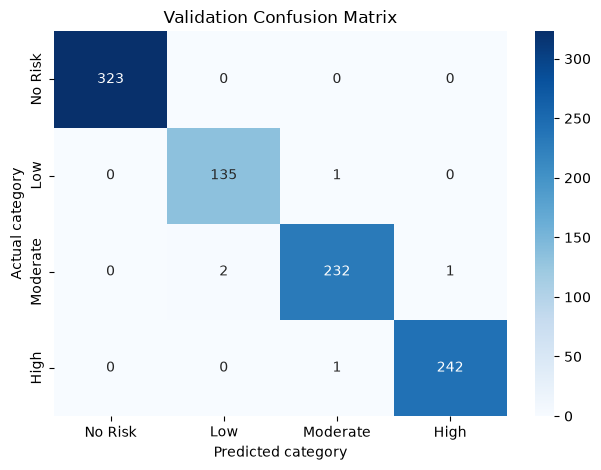

In [10]:
category_cm=confusion_matrix(true_categories,predicted_categories,labels=CATEGORY_ORDER)
display(pd.DataFrame(category_cm,index=CATEGORY_ORDER,columns=CATEGORY_ORDER))
sns.heatmap(category_cm,annot=True,fmt="d",cmap="Blues",xticklabels=CATEGORY_ORDER,yticklabels=CATEGORY_ORDER)
plt.xlabel("Predicted category"); plt.ylabel("Actual category"); plt.title("Validation Confusion Matrix"); plt.tight_layout(); plt.show()

## 11. Prediction Plots and Feature Importance

Feature importance reflects this forest's split choices; it does not show causal effects.

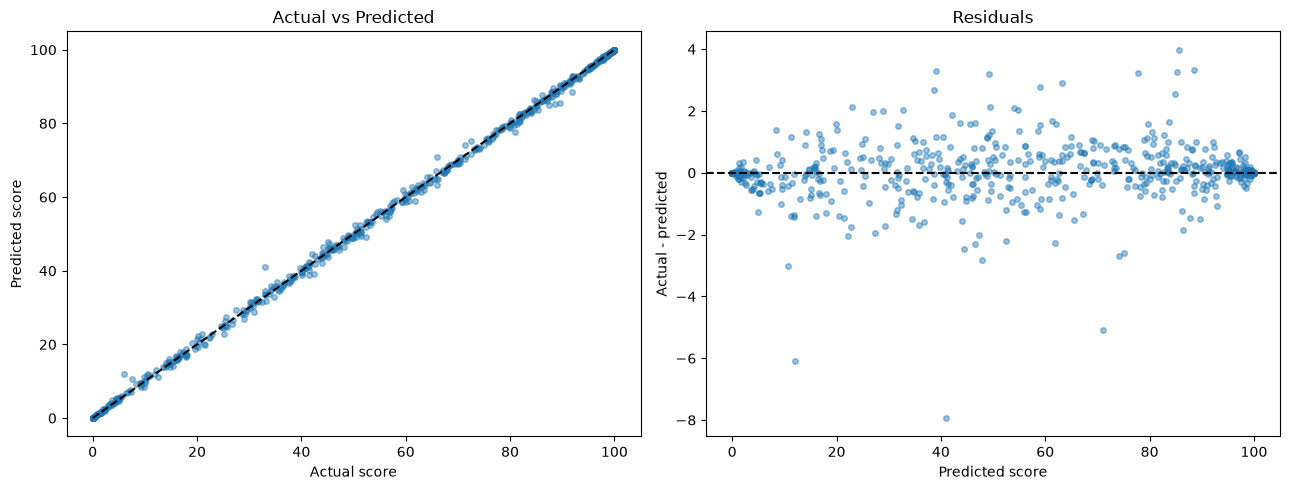

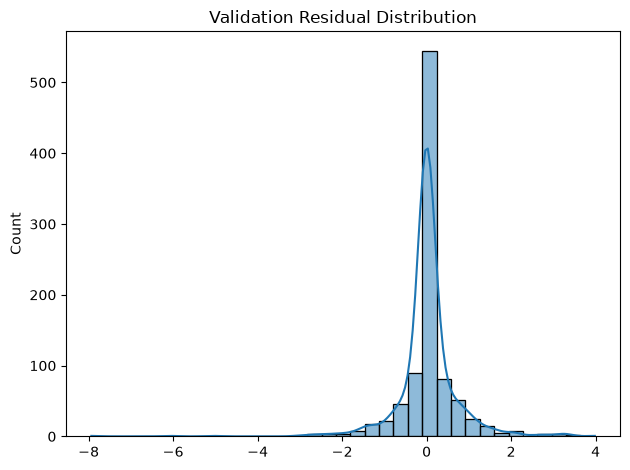

,importance
estimated_leaf_wet,4.439856e-08
air_temp_c,4.062052e-01
consecutive_wetness_hours,5.937948e-01


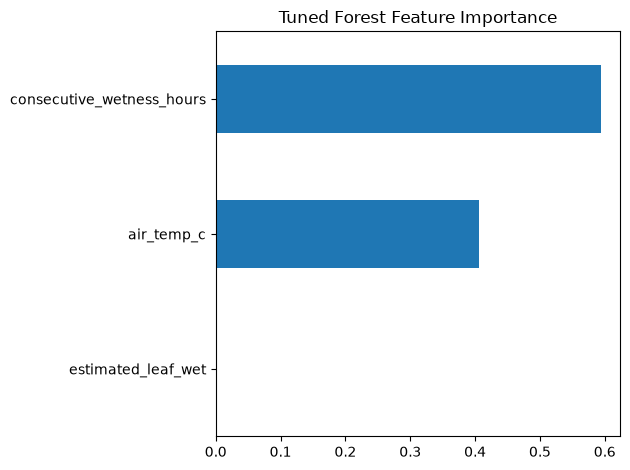

In [11]:
residuals=y_val.to_numpy()-tuned_val_pred
fig,ax=plt.subplots(1,2,figsize=(13,5))
ax[0].scatter(y_val,tuned_val_pred,alpha=.45,s=16); ax[0].plot([0,100],[0,100],"--",color="black"); ax[0].set(xlabel="Actual score",ylabel="Predicted score",title="Actual vs Predicted")
ax[1].scatter(tuned_val_pred,residuals,alpha=.45,s=16); ax[1].axhline(0,ls="--",color="black"); ax[1].set(xlabel="Predicted score",ylabel="Actual - predicted",title="Residuals")
plt.tight_layout(); plt.show()
sns.histplot(residuals,bins=35,kde=True); plt.title("Validation Residual Distribution"); plt.tight_layout(); plt.show()
importance=pd.Series(best_model.feature_importances_,index=FEATURES).sort_values()
display(importance.rename("importance").to_frame()); importance.plot.barh(title="Tuned Forest Feature Importance"); plt.tight_layout(); plt.show()

## 12. Save and Reload Check

The canonical project model stays untouched. A temporary copy verifies serialization and prediction consistency.

In [12]:
with tempfile.TemporaryDirectory() as temp_dir:
    temp_model=Path(temp_dir)/"random_forest_model.joblib"
    joblib.dump(best_model,temp_model)
    reloaded=joblib.load(temp_model)
    np.testing.assert_allclose(reloaded.predict(X_val),tuned_val_pred,rtol=0,atol=1e-12)
existing_model=joblib.load(saved_model_path)
np.testing.assert_allclose(existing_model.predict(X_val),tuned_val_pred,rtol=0,atol=1e-10)
print("Temporary save/load and existing model predictions match.")

Temporary save/load and existing model predictions match.


## 13. Compare Existing Reports and Protect Inputs

The saved reports and model are preserved. These checks confirm that this run matches the existing evaluation before any future artifact update.

In [13]:
report_dir=PROJECT_ROOT/"reports/black_sigatoka/random_forest"
saved_comparison=pd.read_csv(report_dir/"model_comparison.csv")
assert saved_comparison.model.tolist()==model_comparison.model.tolist()
metric_cols=["train_mae","train_rmse","train_r2","validation_mae","validation_rmse","validation_r2"]
np.testing.assert_allclose(saved_comparison[metric_cols],model_comparison[metric_cols],rtol=0,atol=1e-10)
saved_predictions=pd.read_csv(report_dir/"validation_predictions.csv")
assert saved_predictions.scenario_id.tolist()==frames["validation"].scenario_id.tolist()
np.testing.assert_allclose(saved_predictions.raw_predicted_risk_score,tuned_val_pred,rtol=0,atol=1e-10)
saved_cm=pd.read_csv(report_dir/"validation_confusion_matrix.csv",index_col=0)
np.testing.assert_array_equal(saved_cm.loc[CATEGORY_ORDER,CATEGORY_ORDER].to_numpy(),category_cm)
saved_report=pd.read_csv(report_dir/"validation_classification_report.csv").set_index("category")
for cat in CATEGORY_ORDER+["macro avg","weighted avg"]:
    np.testing.assert_allclose(saved_report.loc[cat,["precision","recall","f1_score"]].to_numpy(float),classification_table.loc[cat,["precision","recall","f1-score"]].to_numpy(float),rtol=0,atol=1e-10)
config=json.loads((report_dir/"training_config.json").read_text(encoding="utf-8"))
assert config["candidate_count"]==len(tuning_results) and config["test_dataset_loaded_for_modeling"] is False
protected_after={str(p.relative_to(PROJECT_ROOT)):sha256_file(p) for p in protected_paths}
assert protected_after==protected_before
print("Existing reports match; all CSV/model checksums are unchanged.")

Existing reports match; all CSV/model checksums are unchanged.


## 14. Results and Limitations

The target values are constructed risk scores, not confirmed infection outcomes. High metrics measure imitation of those synthetic labels, not validated biological disease detection. The score generator is unavailable; six repeated feature combinations have differing scores; and simulated weather is not historical NASA data. Validation was used for tuning, so use a separate untouched test evaluation before generalization claims. Measured plantation weather and confirmed disease observations are needed for biological validation.

## Final Model Results

These values come from the training and validation predictions calculated above.

In [14]:
# Show the final metrics
final_metrics = pd.DataFrame([
    ("Training MAE", regression_metrics(y_train, tuned_train_pred)["MAE"]),
    ("Validation MAE", regression_metrics(y_val, tuned_val_pred)["MAE"]),
    ("Training RMSE", regression_metrics(y_train, tuned_train_pred)["RMSE"]),
    ("Validation RMSE", regression_metrics(y_val, tuned_val_pred)["RMSE"]),
    ("Training R-squared", regression_metrics(y_train, tuned_train_pred)["R2"]),
    ("Validation R-squared", regression_metrics(y_val, tuned_val_pred)["R2"]),
    ("Validation category accuracy", category_accuracy),
    ("Validation macro precision", classification_table.loc["macro avg", "precision"]),
    ("Validation macro recall", classification_table.loc["macro avg", "recall"]),
    ("Validation macro F1-score", classification_table.loc["macro avg", "f1-score"]),
    ("Validation weighted F1-score", classification_table.loc["weighted avg", "f1-score"]),
], columns=["Metric", "Value"])
final_metrics["Value"] = final_metrics["Value"].map(lambda value: f"{value:.4f}")
display(final_metrics)

# Check F1-score
category_f1 = classification_table.loc[CATEGORY_ORDER, ["f1-score"]].rename_axis("Risk level")
category_f1 = category_f1.rename(columns={"f1-score": "F1-score"}).reset_index()
category_f1["F1-score"] = category_f1["F1-score"].map(lambda value: f"{value:.4f}")
display(category_f1)

,Metric,Value
0,Training MAE,0.1227
1,Validation MAE,0.3633
2,Training RMSE,0.2517
3,Validation RMSE,0.7543
4,Training R-squared,1.0000
5,Validation R-squared,0.9996
6,Validation category accuracy,0.9947
7,Validation macro precision,0.9932
8,Validation macro recall,0.9939
9,Validation macro F1-score,0.9936


,Risk level,F1-score
0,No Risk,1.0000
1,Low,0.9890
2,Moderate,0.9893
3,High,0.9959


## Validation Prediction Examples

Five examples from the existing validation predictions are shown below.

In [15]:
# Show a few predictions
example_rows = frames["validation"].iloc[:5][FEATURES + [TARGET, "risk_level"]].copy()
example_rows["predicted_risk_score"] = tuned_val_pred[:5]
example_rows["predicted_risk_level"] = predicted_categories.iloc[:5].to_numpy()
prediction_examples = example_rows.rename(columns={
    "air_temp_c": "Air temperature (C)",
    "estimated_leaf_wet": "Estimated leaf wetness",
    "consecutive_wetness_hours": "Consecutive wetness hours",
    TARGET: "Actual risk score",
    "risk_level": "Actual risk level",
    "predicted_risk_score": "Predicted risk score",
    "predicted_risk_level": "Predicted risk level",
})
prediction_examples["Actual risk score"] = prediction_examples["Actual risk score"].map(lambda value: f"{value:.4f}")
prediction_examples["Predicted risk score"] = prediction_examples["Predicted risk score"].map(lambda value: f"{value:.4f}")
display(prediction_examples)

,Air temperature (C),Estimated leaf wetness,Consecutive wetness hours,Actual risk score,Actual risk level,Predicted risk score,Predicted risk level
0,30.865,0,0,0.0000,No Risk,0.0000,No Risk
1,22.044,1,92,81.6215,High,81.5561,High
2,28.262,1,69,96.6965,High,96.8654,High
3,33.120,0,0,0.0000,No Risk,0.0000,No Risk
4,22.960,1,31,31.4656,Moderate,32.3497,Moderate


## How This Model Works

1. We load the environmental training data.
2. Random Forest creates multiple decision trees.
3. Each tree learns relationships between environmental features and synthetic risk scores.
4. The model averages predictions from the trees.
5. We compare its predictions with validation scores.
6. We convert predicted scores into four risk levels.